# Compute Latency

This example demonstrates how to use direct function calls of the low-level TAT-C library to perform latency analysis.

Similar to the _Collect Observations_ and _Compute Coverage_ examples, the first steps are to define the satellites for the mission. This example again uses the NOAA-20 satellite with a two-line elements model from July 2022 and a VIIRS instrument with field of regard computed based on a 834km altitude and 3000km swath width. Unlike the coverage example, the instrument requires the target to be sunlit, so only daytime observations are collected. Points are distributed over the globe with a 5000 km characteristic distance and observations are collected over a 30 day period starting on July 14, 2022 at noon UTC.

In [1]:
from tatc import utils
from tatc.schemas import GeneralPerturbationsOrbit, Instrument, Satellite

viirs = Instrument(
    name="VIIRS",
    field_of_regard=utils.swath_width_to_field_of_regard(834000, 3000000),
    req_target_sunlit=True,
)
noaa20 = Satellite(
    name="NOAA 20",
    orbit=GeneralPerturbationsOrbit.from_tle(
        [
            "1 43013U 17073A   22195.78278435  .00000038  00000+0  38919-4 0  9996",
            "2 43013  98.7169 133.9110 0001202  63.8768 296.2532 14.19561306241107",
        ]
    ),
    instruments=[viirs],
)

from tatc.generation import generate_points_uniform_spacing

points_df = generate_points_uniform_spacing(5000e3)

points = list(points_df.geometry)

from datetime import datetime, timedelta, timezone

start = datetime(year=2022, month=7, day=14, hour=12, tzinfo=timezone.utc)
end = start + timedelta(days=30)

from tatc.analysis import collect_observations
import pandas as pd

# the observations of all points, collected together
observations = collect_observations(points, noaa20, start, end)
display(observations)

,target_hash,geometry,satellite,instrument,start,end,epoch,platform_alt,platform_az
0,ffda02e42c0f192c,POINT Z (22.34708 22.41505 0),NOAA 20,VIIRS,2022-07-14 12:03:52.827364559+00:00,2022-07-14 12:10:35.639813131+00:00,2022-07-14 12:07:14.233588845+00:00,46.695823,259.484714
1,8e011e9f0bc6edbd,POINT Z (22.34708 67.38106 0),NOAA 20,VIIRS,2022-07-14 12:17:33.123086641+00:00,2022-07-14 12:22:29.184948494+00:00,2022-07-14 12:20:01.154017567+00:00,29.030770,270.896458
2,ffd1162f19c00a90,POINT Z (-22.61894 67.38106 0),NOAA 20,VIIRS,2022-07-14 12:18:12.169729496+00:00,2022-07-14 12:25:02.577119910+00:00,2022-07-14 12:21:37.373424703+00:00,48.704782,49.412002
3,fac4abea2ef57cbc,POINT Z (-112.55097 67.38106 0),NOAA 20,VIIRS,2022-07-14 12:27:38.698255738+00:00,2022-07-14 12:32:54.980518695+00:00,2022-07-14 12:30:16.839387217+00:00,31.323370,324.706136
4,ae8ba93ad8c5225f,POINT Z (-157.51699 67.38106 0),NOAA 20,VIIRS,2022-07-14 12:29:19.068957730+00:00,2022-07-14 12:36:29.622971584+00:00,2022-07-14 12:32:54.345964657+00:00,55.693820,102.974087
...,...,...,...,...,...,...,...,...,...
2357,03a64c9b608df33d,POINT Z (67.3131 -67.51699 0),NOAA 20,VIIRS,2022-08-13 10:33:48.182712199+00:00,2022-08-13 10:41:29.770915854+00:00,2022-08-13 10:37:38.976814027+00:00,78.729024,238.633588
2358,ffda02e42c0f192c,POINT Z (22.34708 22.41505 0),NOAA 20,VIIRS,2022-08-13 11:01:25.476997073+00:00,2022-08-13 11:07:14.254019417+00:00,2022-08-13 11:04:19.865508245+00:00,35.630865,73.052139
2359,8e011e9f0bc6edbd,POINT Z (22.34708 67.38106 0),NOAA 20,VIIRS,2022-08-13 11:12:44.463800711+00:00,2022-08-13 11:19:57.113450374+00:00,2022-08-13 11:16:20.788625542+00:00,56.674411,256.787973
2360,ffd1162f19c00a90,POINT Z (-22.61894 67.38106 0),NOAA 20,VIIRS,2022-08-13 11:16:22.751386292+00:00,2022-08-13 11:21:36.829593549+00:00,2022-08-13 11:18:59.790489921+00:00,31.049476,34.877751


Latency analysis measures the interval between each observation and its first downlink opportunity at any ground station (by default, the midpoint of the next contact, or the end of a contact in progress when the observation ends). The following specifies a ground station at Hoboken with a 10-degree minimum elevation angle for downlink.

In [2]:
from tatc.schemas import GroundStation

hoboken = GroundStation(
    id=0, name="Hoboken", latitude=40.74259, longitude=-74.02686, min_elevation_angle=10
)

from tatc.analysis import collect_downlinks

downlinks = collect_downlinks(hoboken, noaa20, start, end)
display(downlinks)

,ground_station,geometry,satellite,start,end,epoch
0,Hoboken,POINT Z (-74.02686 40.74259 0),NOAA 20,2022-07-14 17:12:43.761284+00:00,2022-07-14 17:22:57.440354+00:00,2022-07-14 17:17:50.600819+00:00
1,Hoboken,POINT Z (-74.02686 40.74259 0),NOAA 20,2022-07-14 18:54:04.788610+00:00,2022-07-14 19:02:24.918225+00:00,2022-07-14 18:58:14.853417+00:00
2,Hoboken,POINT Z (-74.02686 40.74259 0),NOAA 20,2022-07-15 05:32:06.511405+00:00,2022-07-15 05:39:35.851796+00:00,2022-07-15 05:35:51.181600+00:00
3,Hoboken,POINT Z (-74.02686 40.74259 0),NOAA 20,2022-07-15 07:11:08.218022+00:00,2022-07-15 07:21:37.024951+00:00,2022-07-15 07:16:22.621486+00:00
4,Hoboken,POINT Z (-74.02686 40.74259 0),NOAA 20,2022-07-15 16:54:27.763367+00:00,2022-07-15 17:03:52.146465+00:00,2022-07-15 16:59:09.954916+00:00
...,...,...,...,...,...,...
123,Hoboken,POINT Z (-74.02686 40.74259 0),NOAA 20,2022-08-12 08:28:06.674162+00:00,2022-08-12 08:32:42.109160+00:00,2022-08-12 08:30:24.391661+00:00
124,Hoboken,POINT Z (-74.02686 40.74259 0),NOAA 20,2022-08-12 16:30:10.542785+00:00,2022-08-12 16:37:44.323949+00:00,2022-08-12 16:33:57.433367+00:00
125,Hoboken,POINT Z (-74.02686 40.74259 0),NOAA 20,2022-08-12 18:08:25.793127+00:00,2022-08-12 18:19:01.105513+00:00,2022-08-12 18:13:43.449320+00:00
126,Hoboken,POINT Z (-74.02686 40.74259 0),NOAA 20,2022-08-13 06:26:49.023192+00:00,2022-08-13 06:37:29.389020+00:00,2022-08-13 06:32:09.206106+00:00


Finally, latencies are computed by comparing the observations and downlink opportunities.

In [3]:
from tatc.analysis import compute_latencies

latencies = compute_latencies(observations, downlinks)
display(latencies)

,target_hash,geometry,satellite,instrument,platform_alt,platform_az,ground_station,downlinked,latency,observed
0,ffda02e42c0f192c,POINT Z (22.34708 22.41505 0),NOAA 20,VIIRS,46.695823,259.484714,Hoboken,2022-07-14 17:17:50.600819+00:00,0 days 05:10:36.367230155,2022-07-14 12:07:14.233588845+00:00
1,8e011e9f0bc6edbd,POINT Z (22.34708 67.38106 0),NOAA 20,VIIRS,29.030770,270.896458,Hoboken,2022-07-14 17:17:50.600819+00:00,0 days 04:57:49.446801433,2022-07-14 12:20:01.154017567+00:00
2,ffd1162f19c00a90,POINT Z (-22.61894 67.38106 0),NOAA 20,VIIRS,48.704782,49.412002,Hoboken,2022-07-14 17:17:50.600819+00:00,0 days 04:56:13.227394297,2022-07-14 12:21:37.373424703+00:00
3,fac4abea2ef57cbc,POINT Z (-112.55097 67.38106 0),NOAA 20,VIIRS,31.323370,324.706136,Hoboken,2022-07-14 17:17:50.600819+00:00,0 days 04:47:33.761431783,2022-07-14 12:30:16.839387217+00:00
4,ae8ba93ad8c5225f,POINT Z (-157.51699 67.38106 0),NOAA 20,VIIRS,55.693820,102.974087,Hoboken,2022-07-14 17:17:50.600819+00:00,0 days 04:44:56.254854343,2022-07-14 12:32:54.345964657+00:00
...,...,...,...,...,...,...,...,...,...,...
2357,03a64c9b608df33d,POINT Z (67.3131 -67.51699 0),NOAA 20,VIIRS,78.729024,238.633588,NaN,NaT,NaT,2022-08-13 10:37:38.976814027+00:00
2358,ffda02e42c0f192c,POINT Z (22.34708 22.41505 0),NOAA 20,VIIRS,35.630865,73.052139,NaN,NaT,NaT,2022-08-13 11:04:19.865508245+00:00
2359,8e011e9f0bc6edbd,POINT Z (22.34708 67.38106 0),NOAA 20,VIIRS,56.674411,256.787973,NaN,NaT,NaT,2022-08-13 11:16:20.788625542+00:00
2360,ffd1162f19c00a90,POINT Z (-22.61894 67.38106 0),NOAA 20,VIIRS,31.049476,34.877751,NaN,NaT,NaT,2022-08-13 11:18:59.790489921+00:00


Similar to _Compute Coverage_, latency analysis can also be reduced to compute descriptive statistics for each observation point.

In [4]:
from tatc.analysis import reduce_latencies

reduced_results = reduce_latencies(latencies)
display(reduced_results)

,target_hash,geometry,latency,samples
0,018dc6e30428c685,POINT Z (67.3131 -22.55097 0),0 days 07:40:00.880300997,36
1,03a64c9b608df33d,POINT Z (67.3131 -67.51699 0),0 days 07:51:32.077788089,35
2,175cd17d3ecde055,POINT Z (112.27912 67.38106 0),0 days 04:57:50.779631821,189
3,2132a8d6ebffef15,POINT Z (112.27912 -67.51699 0),0 days 00:57:49.827382979,36
4,31a756edf646f318,POINT Z (112.27912 -22.55097 0),0 days 00:45:24.857940570,35
5,337f347a68f89b5f,POINT Z (22.34708 -67.51699 0),0 days 04:52:42.261874928,35
6,3782c3b68daa58bd,POINT Z (-67.58495 -67.51699 0),0 days 01:40:16.749223026,35
7,3dded23526d813bc,POINT Z (22.34708 -22.55097 0),0 days 04:34:31.722222466,35
8,3e4cfcd1e7d9d471,POINT Z (-67.58495 22.41505 0),0 days 00:10:26.852452314,34
9,41fffa8fa3273adc,POINT Z (-22.61894 -22.55097 0),0 days 01:34:45.214196603,35


Finally, GeoPandas and Cartopy can visualize the geospatial data.

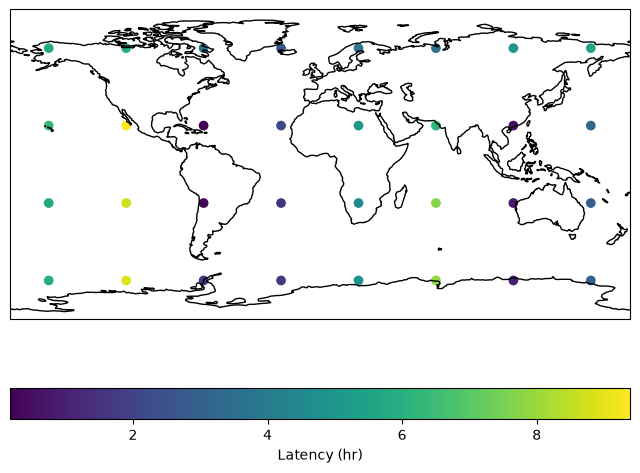

In [5]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

reduced_results["latency_hr"] = reduced_results.latency / timedelta(hours=1)

fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()})
reduced_results.plot(
    column="latency_hr",
    legend=True,
    legend_kwds={"label": "Latency (hr)", "orientation": "horizontal"},
    ax=ax,
    transform=ccrs.PlateCarree(),
)
ax.coastlines()
ax.set_global()
plt.show()

Similar to _Compute Coverage_, cells can also be used for spatial aggregation.

In [6]:
from tatc.generation.cells import generate_cells_uniform_spacing

cells_df = generate_cells_uniform_spacing(5000e3)

from tatc.analysis.latency_sampling import grid_latencies

grid_results = grid_latencies(reduced_results, cells_df)
grid_results["latency_hr"] = grid_results["latency"] / timedelta(hours=1)
display(grid_results)

,cell_id,geometry,samples,latency,latency_hr
0,063c7b6c6320ed34,"POLYGON Z ((-90.06796 -90 0, -90.06796 -45.033...",36,0 days 08:55:02.106129171,8.917252
1,0adbc10585808ebf,"POLYGON Z ((-135.03398 -0.06796 0, -135.03398 ...",35,0 days 06:21:01.911549303,6.350531
2,0d4f2bc11ee3c1f2,"POLYGON Z ((-45.10194 -0.06796 0, -45.10194 44...",34,0 days 00:10:26.852452314,0.174126
3,21aa88b060d17822,"POLYGON Z ((-90.06796 44.89806 0, -90.06796 89...",189,0 days 05:57:11.330282829,5.953147
4,2aa5116938471373,"POLYGON Z ((-45.10194 -90 0, -45.10194 -45.033...",35,0 days 01:40:16.749223026,1.671319
5,4045fd286a269d15,"POLYGON Z ((44.83009 -45.03398 0, 44.83009 -0....",35,0 days 04:34:31.722222466,4.575478
6,4330adb8259a3974,"POLYGON Z ((179.72815 -0.06796 0, 179.72815 44...",35,0 days 03:12:37.391368704,3.210386
7,4618365abb69faab,"POLYGON Z ((179.72815 -90 0, 179.72815 -45.033...",37,0 days 02:59:12.699699056,2.986861
8,4997d4cb0f198482,"POLYGON Z ((89.79611 -90 0, 89.79611 -45.03398...",35,0 days 07:51:32.077788089,7.858910
9,4a49fb4a02b63d90,"POLYGON Z ((134.76213 -90 0, 134.76213 -45.033...",36,0 days 00:57:49.827382979,0.963841


Finally, plotting can illustrate the latency over global regions.

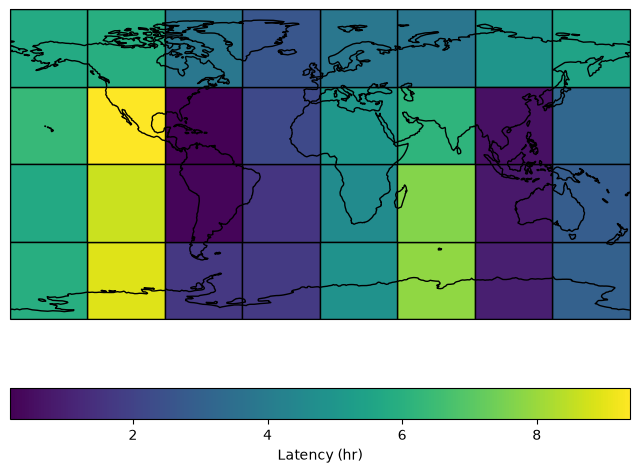

In [7]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()})
grid_results.plot(
    column="latency_hr",
    cmap="viridis",
    edgecolor="k",
    legend=True,
    legend_kwds={"label": "Latency (hr)", "orientation": "horizontal"},
    ax=ax,
)
ax.coastlines()
ax.set_global()
plt.show()